In [50]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

from matplotlib.patches import Rectangle
from matplotlib.animation import FuncAnimation, PillowWriter
from numpy.lib.stride_tricks import sliding_window_view
from scipy.ndimage import gaussian_filter
from skimage import data
from skimage.transform import resize
from IPython.display import display, Image

# Editorial Blueprint palette (matches blueprint.typ)
PAPER    = "#F7F6F0"
ALLOY    = "#EAE7DC"
INK      = "#111214"
VOLTA    = "#FFD100"
GRAPHITE = "#5C626E"

plt.rcParams.update({
    "figure.facecolor": PAPER,
    "savefig.facecolor": PAPER,
    "axes.facecolor": ALLOY,
    "axes.edgecolor": INK,
    "axes.linewidth": 1.0,
    "text.color": INK,
    "axes.titlecolor": INK,
    "xtick.color": GRAPHITE,
    "ytick.color": GRAPHITE,
    "font.family": "sans-serif",
    "font.sans-serif": ["Space Grotesk", "Inter", "DejaVu Sans"],
    "font.monospace": ["JetBrains Mono", "DejaVu Sans Mono"],
    "savefig.bbox": "tight",
})


In [51]:
GAUSSIAN_SIGMA = 1.4

BILATERAL_RADIUS = 3 # neighborhood radius; window is (2*r + 1)²
BILATERAL_SIGMA_SPACE = 2.5
BILATERAL_SIGMA_RANGE = 0.12


OUTPUT_GIF = "gaussian_vs_bilateral_blueprint.gif"
FPS = 12
SCAN_FRAMES = 180
HOLD_FRAMES = 36
DPI = 100


NOISE = 0.08
RANDOM_SEED = 42

In [52]:


n = 128
yy, xx = np.mgrid[:n, :n]

img = np.full((n, n), 0.25)

# Large bright region
img[15:110, 15:110] = 0.72

# Dark rectangle
img[30:65, 28:65] = 0.12

# Bright circle
img[(yy-85)**2 + (xx-85)**2 < 18**2] = 0.95

# Thin dark lines
img[72:75, 20:108] = 0.05
img[20:108, 72:75] = 0.05

# Fine texture in one region
texture = 0.04 * np.sin(xx * 1.5) * np.sin(yy * 1.5)
img[85:108, 18:55] += texture[85:108, 18:55]

img = np.clip(img, 0, 1)

rng = np.random.default_rng(RANDOM_SEED)
noisy = np.clip(img + rng.normal(0, NOISE, img.shape), 0, 1)

print(f"Noise σ: {NOISE}")

Noise σ: 0.08


In [53]:
def bilateral_filter(image, radius=3, sigma_space=2.5, sigma_range=0.12):
    """Apply a bilateral filter to a 2D grayscale image."""
    if image.ndim != 2:
        raise ValueError("bilateral_filter expects a 2D grayscale image.")
    if radius < 1:
        raise ValueError("radius must be >= 1.")
    if sigma_space <= 0 or sigma_range <= 0:
        raise ValueError("Both sigma values must be positive.")

    yy, xx = np.mgrid[-radius:radius+1, -radius:radius+1]
    spatial_weights = np.exp(
        -(yy**2 + xx**2) / (2 * sigma_space**2)
    )

    padded = np.pad(image, radius, mode="reflect")
    patches = sliding_window_view(
        padded, (2*radius + 1, 2*radius + 1)
    )
    center = image[:, :, None, None]

    range_weights = np.exp(
        -((patches - center)**2) / (2 * sigma_range**2)
    )
    weights = spatial_weights[None, None, :, :] * range_weights

    numerator = np.sum(weights * patches, axis=(2, 3))
    denominator = np.sum(weights, axis=(2, 3))
    return numerator / np.maximum(denominator, 1e-12)


gauss = gaussian_filter(noisy, sigma=GAUSSIAN_SIGMA)
bilat = bilateral_filter(
    noisy,
    radius=BILATERAL_RADIUS,
    sigma_space=BILATERAL_SIGMA_SPACE,
    sigma_range=BILATERAL_SIGMA_RANGE
)

def psnr(reference, estimate):
    mse = np.mean((reference - estimate)**2)
    return np.inf if mse == 0 else 10 * np.log10(1.0 / mse)

print(f"Noisy PSNR:    {psnr(img, noisy):.2f} dB")
print(f"Gaussian PSNR: {psnr(img, gauss):.2f} dB")
print(f"Bilateral PSNR:{psnr(img, bilat):.2f} dB")

Noisy PSNR:    22.10 dB
Gaussian PSNR: 21.64 dB
Bilateral PSNR:30.09 dB


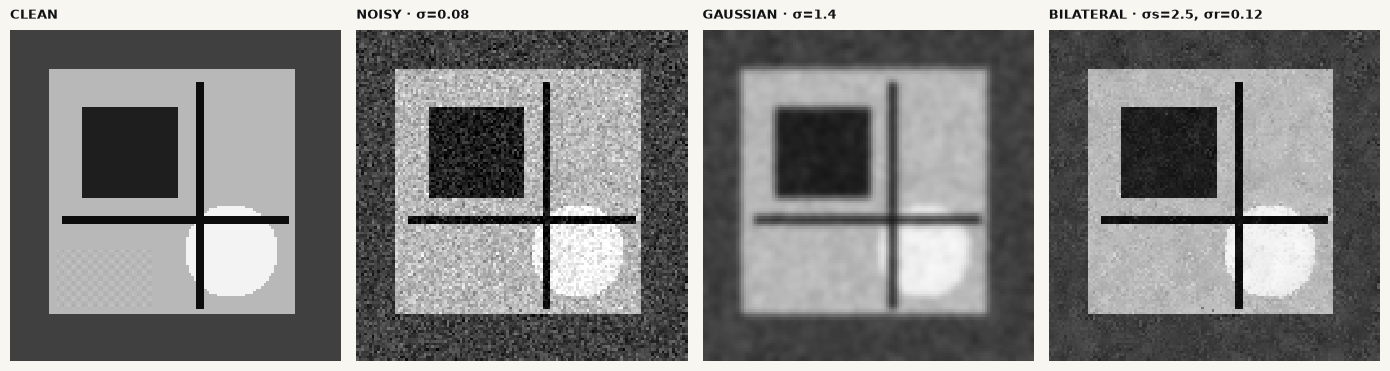

In [54]:
fig, ax = plt.subplots(1, 4, figsize=(14, 4), facecolor=PAPER)

preview_items = [
    (img, "CLEAN"),
    (noisy, f"NOISY · σ={NOISE}"),
    (gauss, f"GAUSSIAN · σ={GAUSSIAN_SIGMA}"),
    (bilat, f"BILATERAL · σs={BILATERAL_SIGMA_SPACE}, σr={BILATERAL_SIGMA_RANGE}")
]

for a, (im, label) in zip(ax, preview_items):
    a.imshow(im, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    a.set_title(label, loc="left", fontsize=9, fontweight="bold", pad=8)
    a.set_xticks([])
    a.set_yticks([])
    a.set_facecolor(ALLOY)
    for spine in a.spines.values():
        spine.set_visible(False)

fig.patch.set_facecolor(PAPER)
plt.tight_layout()
plt.show()

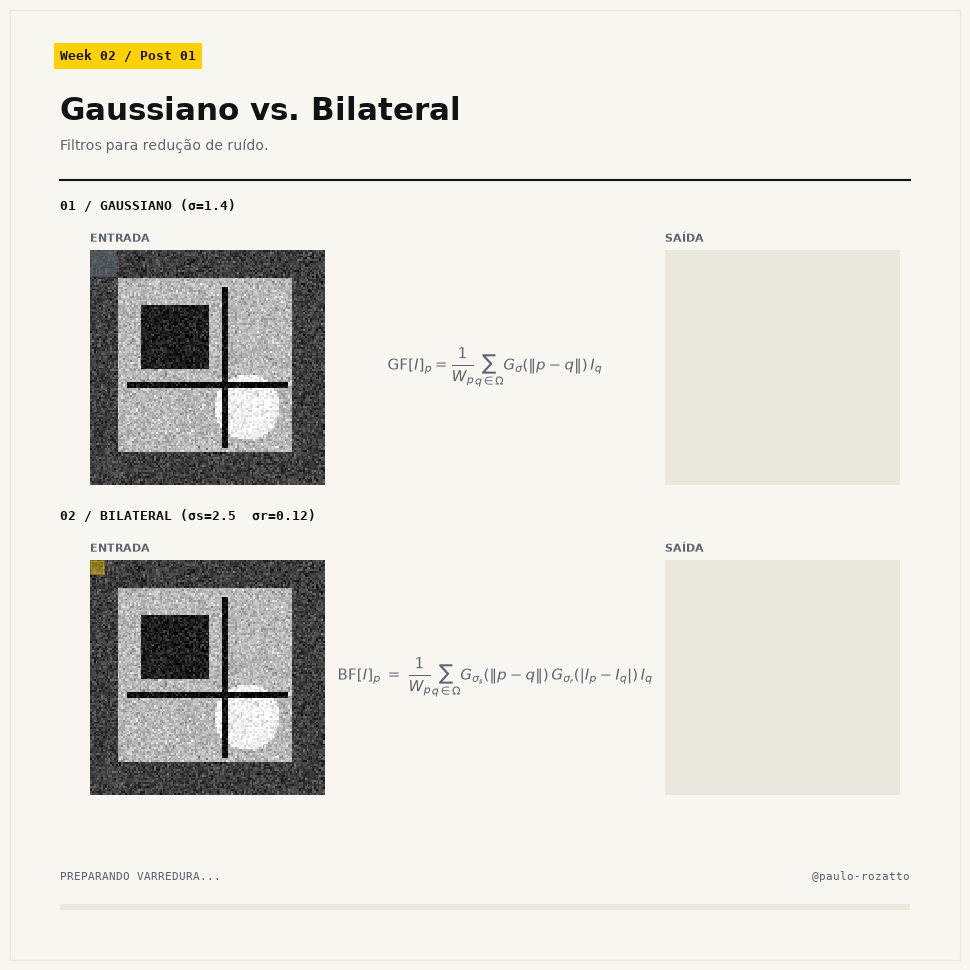

In [55]:
# Calculate the effective Gaussian support used by scipy's default truncate=4.
GAUSSIAN_RADIUS = int(4.0 * GAUSSIAN_SIGMA + 0.5)
GAUSSIAN_WINDOW = 2 * GAUSSIAN_RADIUS + 1
BILATERAL_WINDOW = 2 * BILATERAL_RADIUS + 1

fig = plt.figure(figsize=(10, 10), facecolor=PAPER)

# Signature viewfinder frame
fig.add_artist(Rectangle(
    (0.025, 0.025), 0.95, 0.95,
    transform=fig.transFigure,
    fill=False, edgecolor=ALLOY,
    linewidth=1.0, zorder=0
))

# Header tag
fig.text(
    0.075, 0.925, "Week 02 / Post 01",
    fontsize=9, fontweight="bold",
    color=INK, family="monospace",
    bbox=dict(facecolor=VOLTA, edgecolor="none",
              boxstyle="square,pad=0.45")
)

fig.text(
    0.075, 0.865,
    "Gaussiano vs. Bilateral",
    fontsize=22, fontweight="bold",
    color=INK
)

fig.text(
    0.075, 0.835,
    "Filtros para redução de ruído.",
    fontsize=10, color=GRAPHITE
)

fig.add_artist(plt.Line2D(
    [0.075, 0.925], [0.805, 0.805],
    transform=fig.transFigure,
    color=INK, linewidth=1.5
))

# Panel section labels
fig.text(
    0.075, 0.775,
    f"01 / GAUSSIANO (σ={GAUSSIAN_SIGMA:g})",
    fontsize=9, fontweight="bold", color=INK,
    family="monospace"
)
fig.text(
    0.075, 0.465,
    f"02 / BILATERAL (σs={BILATERAL_SIGMA_SPACE:g}  σr={BILATERAL_SIGMA_RANGE:g})",
    fontsize=9, fontweight="bold", color=INK,
    family="monospace"
)

# ── Filter equations ──────────────────────────────────────
fig.text(
    0.510, 0.6175,
    r"$\mathrm{GF}[I]_p"
    r"=\dfrac{1}{W_p}"
    r"\sum_{q\in\Omega}"
    r"G_\sigma(\|p-q\|)\,I_q$",
    ha="center", va="center", fontsize=11, color=GRAPHITE,
)
fig.text(
   0.510, 0.3075,
    r"$\mathrm{BF}[I]_{p}\;=\;\dfrac{1}{W_{p}}\sum_{q\in\Omega}G_{\sigma_s}(\Vert p-q\Vert)\,G_{\sigma_r}(|I_{p}-I_{q}|)\,I_{q}$",
    ha="center", va="center", fontsize=11, color=GRAPHITE,
)

# Axes positions are tuned for a square editorial composition.
ax_in_g  = fig.add_axes([0.025, 0.500, 0.395, 0.235])
ax_out_g = fig.add_axes([0.6,  0.500, 0.395, 0.235])
ax_in_b  = fig.add_axes([0.025, 0.190, 0.395, 0.235])
ax_out_b = fig.add_axes([0.6,  0.190, 0.395, 0.235])

axes = [ax_in_g, ax_out_g, ax_in_b, ax_out_b]

for ax in axes:
    ax.set_facecolor(ALLOY)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)

# Input images
ax_in_g.imshow(noisy, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
ax_in_b.imshow(noisy, cmap="gray", vmin=0, vmax=1, interpolation="nearest")

# Output images start fully masked; pixels are revealed during animation.
rev_g = np.full_like(noisy, np.nan)
rev_b = np.full_like(noisy, np.nan)

gray_cmap = plt.get_cmap("gray").copy()
gray_cmap.set_bad(alpha=0)

im_out_g = ax_out_g.imshow(
    np.ma.masked_invalid(rev_g),
    cmap=gray_cmap, vmin=0, vmax=1,
    interpolation="nearest"
)
im_out_b = ax_out_b.imshow(
    np.ma.masked_invalid(rev_b),
    cmap=gray_cmap, vmin=0, vmax=1,
    interpolation="nearest"
)

# Panel labels
panel_titles = [
    (ax_in_g, "ENTRADA"),
    (ax_out_g, "SAÍDA"),
    (ax_in_b, "ENTRADA"),
    (ax_out_b, "SAÍDA"),
]

for ax, label in panel_titles:
    ax.set_title(
        label, loc="left", fontsize=8,
        fontweight="bold", color=GRAPHITE, pad=6
    )

# Separate visual windows: Gaussian's effective support is larger.
rect_g = Rectangle(
    (0, 0), GAUSSIAN_WINDOW, GAUSSIAN_WINDOW,
    facecolor=GRAPHITE, alpha=0.62,
    edgecolor=GRAPHITE, linewidth=1.8,
    zorder=10
)
rect_b = Rectangle(
    (0, 0), BILATERAL_WINDOW, BILATERAL_WINDOW,
    facecolor=VOLTA, alpha=0.40,
    edgecolor=VOLTA, linewidth=1.2,
    zorder=10
)

ax_in_g.add_patch(rect_g)
ax_in_b.add_patch(rect_b)

# Footer / live status
status = fig.text(
    0.075, 0.105, "PREPARANDO VARREDURA...",
    fontsize=8, color=GRAPHITE, family="monospace"
)
fig.text(
    0.925, 0.105, "@paulo-rozatto",
    ha="right", fontsize=8, color=GRAPHITE,
    family="monospace"
)

# Progress track
progress_bg = Rectangle(
    (0.075, 0.075), 0.85, 0.006,
    transform=fig.transFigure,
    facecolor=ALLOY, edgecolor="none", zorder=20
)
progress_fg = Rectangle(
    (0.075, 0.075), 0.0, 0.006,
    transform=fig.transFigure,
    facecolor=VOLTA, edgecolor="none", zorder=21
)
fig.add_artist(progress_bg)
fig.add_artist(progress_fg)

plt.show()

# up here

In [56]:
h, w = noisy.shape
positions = [(row, col) for row in range(h) for col in range(w)]

scan_ids = np.linspace(
    0, len(positions) - 1,
    num=min(SCAN_FRAMES, len(positions)),
    dtype=int
)
frame_ids = np.concatenate([
    scan_ids,
    np.repeat(scan_ids[-1], HOLD_FRAMES)
])

def update(frame_number):
    idx = frame_ids[frame_number]
    row, col = positions[idx]

    # Move each visual neighborhood to the current center.
    rect_g.set_xy((
        col - GAUSSIAN_RADIUS - 0.5,
        row - GAUSSIAN_RADIUS - 0.5
    ))
    rect_b.set_xy((
        col - BILATERAL_RADIUS - 0.5,
        row - BILATERAL_RADIUS - 0.5
    ))

    # Reveal output pixels up to the current scan position.
    rev_g.ravel()[:idx + 1] = gauss.ravel()[:idx + 1]
    rev_b.ravel()[:idx + 1] = bilat.ravel()[:idx + 1]

    im_out_g.set_data(np.ma.masked_invalid(rev_g))
    im_out_b.set_data(np.ma.masked_invalid(rev_b))

    progress = (idx + 1) / len(positions)
    progress_fg.set_width(0.85 * progress)

    if frame_number >= len(frame_ids) - HOLD_FRAMES:
        status.set_text(
            "CONCLUÍDO  /  compare as bordas: "
            "Gaussiano suaviza · Bilateral preserva"
        )
    else:
        status.set_text(
            f"SCAN {idx + 1:>5}/{len(positions)}"
            f"   ·   POS ({row:03d}, {col:03d})"
            f"   ·   {progress * 100:5.1f}%"
        )

    return [
        rect_g, rect_b, im_out_g, im_out_b,
        status, progress_fg
    ]

ani = FuncAnimation(
    fig,
    update,
    frames=len(frame_ids),
    interval=1000 / FPS,
    blit=False,
    repeat=False
)

print(f"Animation frames: {len(frame_ids)}")
print(f"GIF duration: approximately {len(frame_ids) / FPS:.1f} seconds")

Animation frames: 216
GIF duration: approximately 18.0 seconds


In [57]:
ani.save(
    OUTPUT_GIF,
    writer=PillowWriter(fps=FPS),
    dpi=DPI,
    savefig_kwargs={"facecolor": PAPER}
)

print(f"Saved: {Path(OUTPUT_GIF).resolve()}")

Saved: /home/paulo/Projects/cv-posts/posts/week_002/001_filtering/gaussian_vs_bilateral_blueprint.gif
